In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from google.colab import files
uploaded = files.upload()

Saving online_retail_II.xlsx to online_retail_II (2).xlsx


In [4]:
file_name = list(uploaded.keys())[0]
sheet1 = pd.read_excel(file_name, sheet_name='Year 2009-2010')
sheet2 = pd.read_excel(file_name, sheet_name='Year 2010-2011')

In [5]:
df = pd.concat([sheet1, sheet2], ignore_index=True)

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [9]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1067371, 8)


In [10]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')


In [11]:
print("\nData Types:")
print(df.dtypes)


Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [12]:
print("\nStatistical Summary:")
df.describe()



Statistical Summary:


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [13]:
print(df.isnull().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [14]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 34335


In [17]:
print("Original Shape:", df.shape)
df = df.drop_duplicates(keep='first')
print("Shape after removing duplicates:", df.shape)

Original Shape: (1067371, 8)
Shape after removing duplicates: (1033036, 8)


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1033036 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  object        
 1   StockCode    1033036 non-null  object        
 2   Description  1028761 non-null  object        
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[ns]
 5   Price        1033036 non-null  float64       
 6   Customer ID  797885 non-null   float64       
 7   Country      1033036 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 70.9+ MB


In [19]:
# Calculate missing values count and percentage
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combine into a summary DataFrame
missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percent
})

print("Null Value Summary:")
print(missing_df.sort_values(by='Missing Values', ascending=False))

Null Value Summary:
             Missing Values  Percentage (%)
Customer ID          235151       22.763098
Description            4275        0.413829
StockCode                 0        0.000000
Invoice                   0        0.000000
Quantity                  0        0.000000
InvoiceDate               0        0.000000
Price                     0        0.000000
Country                   0        0.000000


In [20]:
print("Shape before dropping nulls:", df.shape)
df = df.dropna()
print("Shape after dropping nulls:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())

Shape before dropping nulls: (1033036, 8)
Shape after dropping nulls: (797885, 8)
Remaining missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


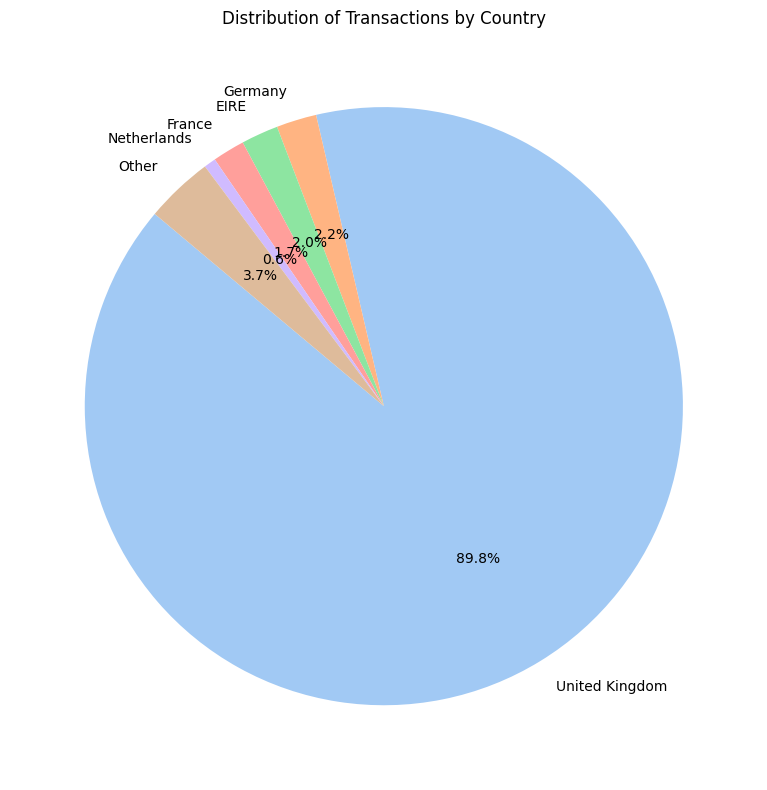

In [22]:
# Get transaction counts per country
country_counts = df['Country'].value_counts()

# Keep top 5 countries and group the rest into 'Other'
top_n = 5
top_countries = country_counts.head(top_n)
other_countries_sum = country_counts.iloc[top_n:].sum()

# Combine top countries with 'Other'
pie_data = pd.concat([top_countries, pd.Series({'Other': other_countries_sum})])

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')
)
plt.title('Distribution of Transactions by Country')
plt.tight_layout()
plt.show()

Total number of return transactions: 18390
Total value of returned/refunded items: £1,084,812.98


/tmp/ipykernel_485/2596973139.py:13: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_returns = returns_df['ReturnAmount'].resample('M').sum()


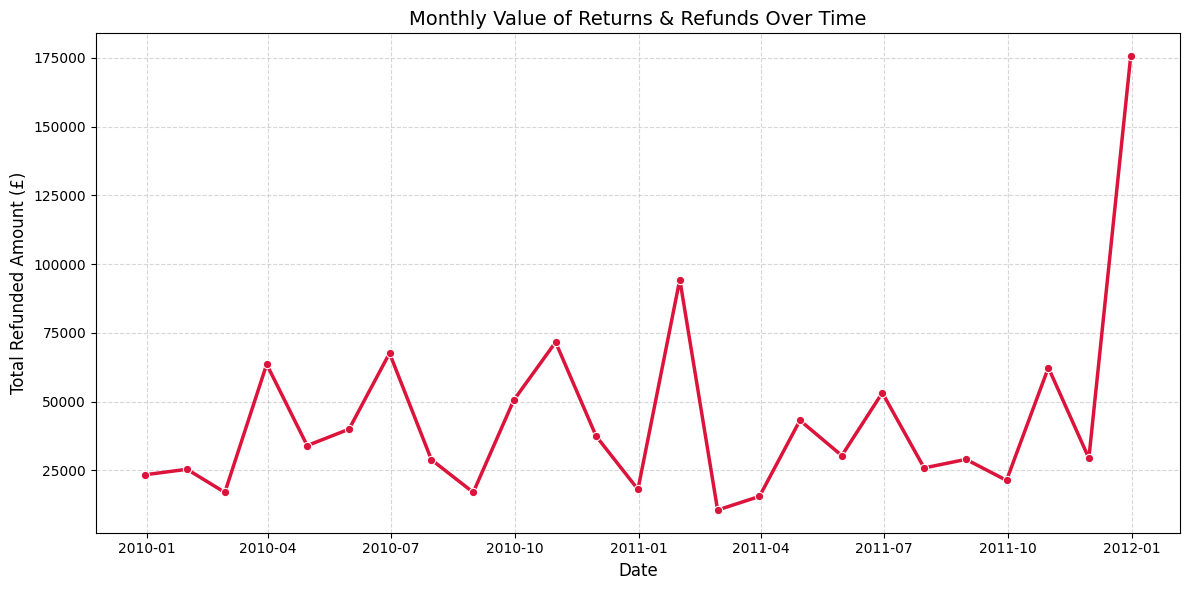

In [24]:
# Identify returns (invoices starting with 'C' or negative quantities)
returns_df = df[(df['Invoice'].astype(str).str.startswith('C')) | (df['Quantity'] < 0)].copy()

# Calculate the total value of returns (Quantity * Price)
returns_df['ReturnAmount'] = (returns_df['Quantity'] * returns_df['Price']).abs()

# Print summary statistics for returns
print(f"Total number of return transactions: {len(returns_df)}")
print(f"Total value of returned/refunded items: £{returns_df['ReturnAmount'].sum():,.2f}")

# Resample returns by month to see the trend over time
returns_df.set_index('InvoiceDate', inplace=True)
monthly_returns = returns_df['ReturnAmount'].resample('M').sum()

# Plot the monthly returns trend
plt.figure(figsize=(12, 6))
sns.lineplot(x=monthly_returns.index, y=monthly_returns.values, marker='o', color='crimson', linewidth=2.5)
plt.title('Monthly Value of Returns & Refunds Over Time', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Refunded Amount (£)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()